# Modes and Gradients

In [16]:
import torch
import torch.nn as nn
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(10,5)
        self.bn = nn.BatchNorm1d(5)
        self.drop = nn.Dropout(0.5)
        self.relu = nn.ReLU()
        self.fc2=nn.Linear(5,1)

    def forward(self,x):
              x = self.relu(self.bn(self.fc(x)))
              return self.fc2(self.drop(x))

model=Net()

## eval() v/s train()

Every module has a flag called training (True or False). train() sets it to True and eval() sets it to False, on the module and every child inside it.

In [17]:
model.eval() # eval() is just a shortcut for train(False)
print(model.training, model.drop.training)   # False False

# model.drop.training tells whetther dropout layer is in training or eval mode

model.train()
print(model.training, model.drop.training)   # True True

False False
True True


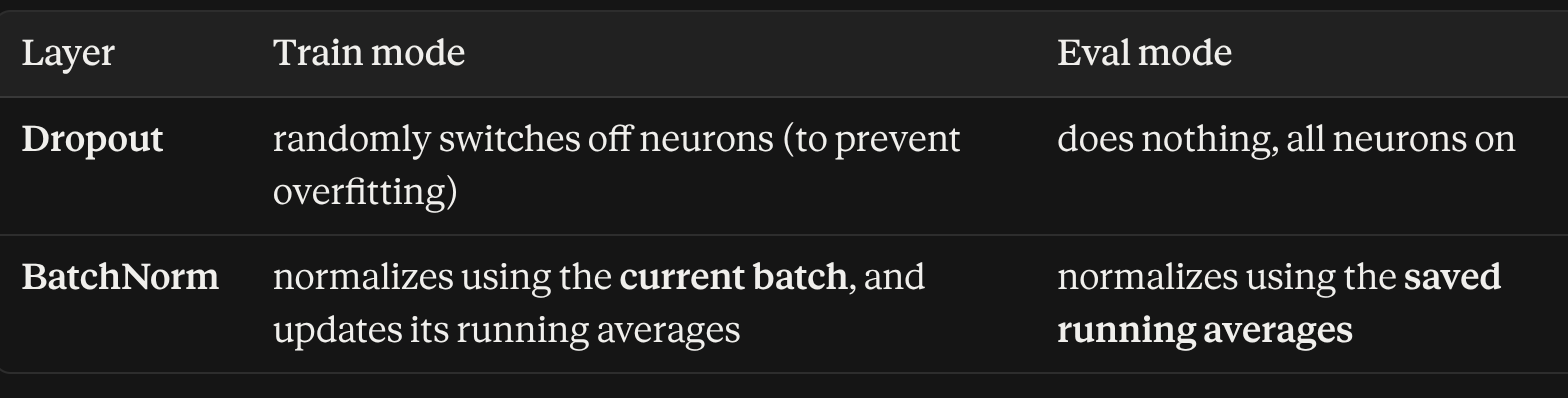

In [18]:
import torch

# We use a batch size of 2 (2 samples, 10 features)
# This batch size works for both evaluation and training modes
x = torch.rand(2, 10)

# --- EVALUATION MODE ---
model.eval()
a = model(x)
b = model(x)
print("Eval Mode Equal?", torch.equal(a, b))    #True

# --- TRAINING MODE ---
model.train()
a = model(x)
b = model(x)
print("Train Mode Equal?", torch.equal(a, b))   #False: dropout randomly changes things each time

Eval Mode Equal? True
Train Mode Equal? False


## If you forget eval() when testing:

Dropout keeps randomly killing neurons, so your predictions are noisy.
BatchNorm uses the tiny test batch's statistics (bad, especially with batch size 1) and also corrupts its running averages.

### A common use: freezing BatchNorm during fine-tuning, while the rest keeps training.

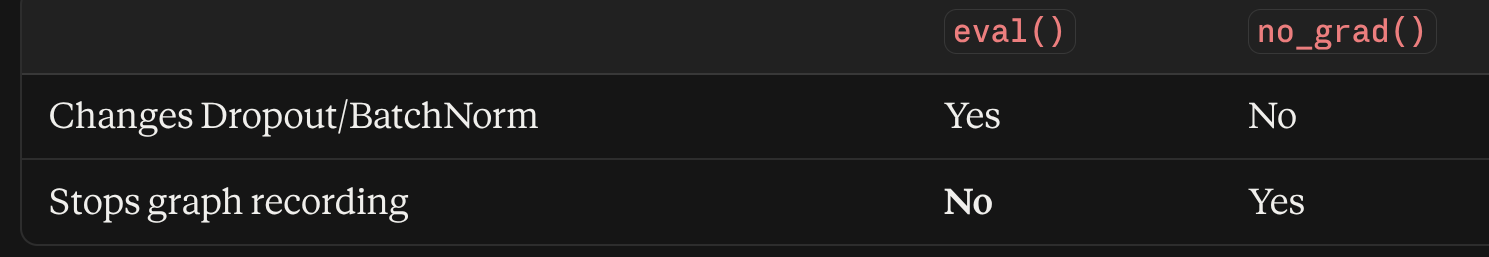

# require_grad()
### Freeze switch

A frozen parameter:

*  gets no gradient (.grad stays None)
* is skipped by the optimizer
* keeps its current values forever

In [19]:
#flip the tracking of the all parameters inside a module
model.fc.requires_grad_(False)
model.fc.requires_grad_(True)

Linear(in_features=10, out_features=5, bias=True)

In [20]:
#check what is still tracking by optimizer
model.fc.requires_grad_(False)
print([n for n, p in model.named_parameters() if p.requires_grad])
# ['bn.weight', 'bn.bias', 'fc2.weight', 'fc2.bias']

['bn.weight', 'bn.bias', 'fc2.weight', 'fc2.bias']


In [21]:
# a frozen batchNorm would still update because it still has the buffre to update

## zer_grad()
Gradients add up. Every backward() call adds to .grad instead of replacing it. This is on purpose (it allows gradient accumulation)

In [22]:
model(x).sum().backward()
print(model.fc.weight.grad is None)    # False: gradient exists

model.zero_grad()
print(model.fc.weight.grad is None)    # True: cleared

### set_to_none

zero_grad(set_to_none=True) is the default in modern PyTorch:
* True: sets .grad to None. Frees memory and is slightly faster.
* False: fills .grad with zeros instead.

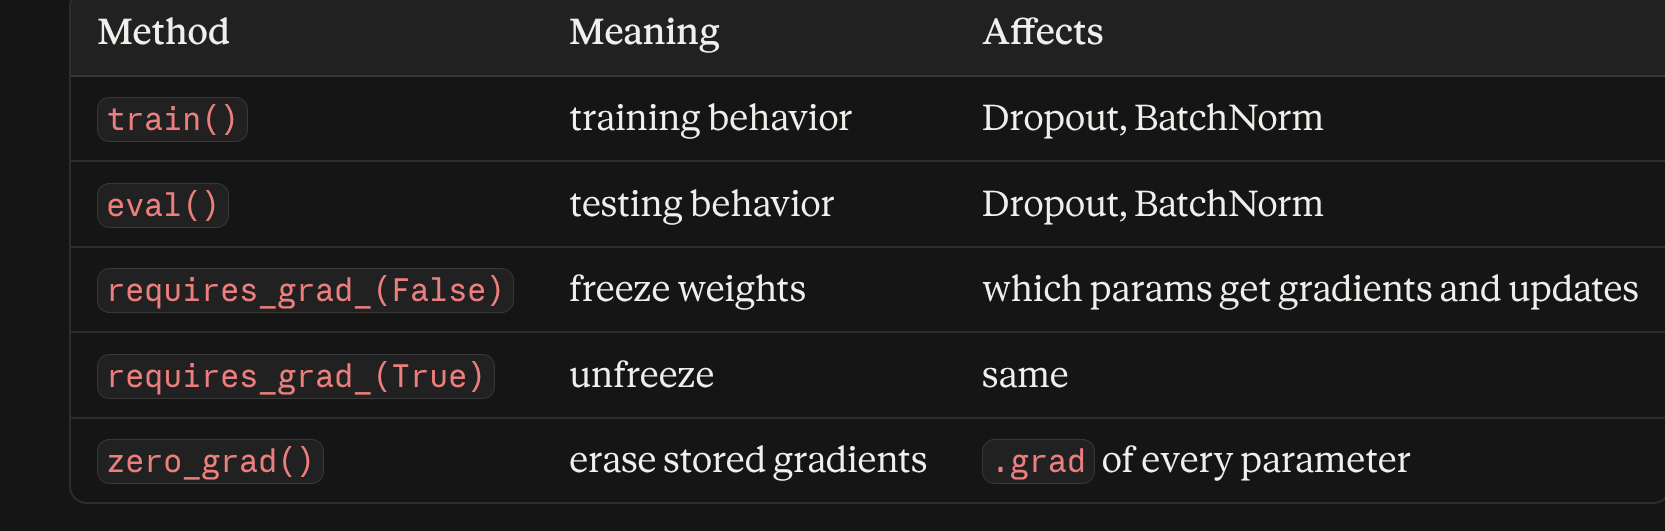